In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import numpy as np
from tqdm import tqdm
import pandas as pd
import copy
import matplotlib.pyplot as plt

import math
from collections import defaultdict

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [42]:
import models

In [9]:
device

device(type='cuda')

# Data: CIFAR-10

In [15]:
# аугментация и предобработка
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),    #https://pytorch.org/vision/main/generated/torchvision.transforms.RandomHorizontalFlip.html
    transforms.RandomCrop(32, padding=4), #https://pytorch.org/vision/main/generated/torchvision.transforms.RandomCrop.html
    transforms.ToTensor(),                # (нормализация в [0, 1]) https://pytorch.org/vision/main/generated/torchvision.transforms.ToTensor.html
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261)) # нормализация по каналам
])

# датасет
trainset = torchvision.datasets.CIFAR10(root='./data_CIFAR10', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data_CIFAR10', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=100, shuffle=False, num_workers=2)

model = WideResNet(depth=28, widen_factor=2).to(device) # модель
criterion = nn.CrossEntropyLoss() # лосс
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4) # ортимизатор
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[60, 120, 160], gamma=0.2) # lr скедулер

Files already downloaded and verified
Files already downloaded and verified


## Class Trainer

Общий технический класс, который принимает:
- DataLoader-ы
- Loss-Function
- Optimizer
- lr-Scheduler

Три основных метода
- Train
- Test
- Отрисовка и доступ к метрикам трейна и теста

In [ ]:
class Trainer:
    """
    Args:
        :model: модель - например WideResNet или VGG
        :trainloader: (DataLoader)
        :testloader: (DataLoader)
        :criterion: (loss) - функция лосса (везде кроссэетропия)
        :optimizer: (torch.optim.sgd) - оптимизатор (везде SGD)
        :scheduler: (torch.optim.lr_scheduler) - расписание лернгрейта (везде MultiStepLR)
    """
    def __init__(self, model, trainloader, testloader, criterion, optimizer, scheduler):
        self.model = model
        self.trainloader = trainloader
        self.testloader = testloader
        self.criterion = criterion
        self.optimizer = optimizer
        self.scheduler = scheduler

        # логирование для картинок
        self.train_losses = []
        self.test_losses = []
        self.train_accs = []
        self.test_accs = []

    def train(self, epoch):
        self.model.train()
        correct, total, running_loss = 0, 0, 0
        for inputs, targets in self.trainloader:
            inputs, targets = inputs.to(device), targets.to(device)
            self.optimizer.zero_grad()
            outputs = self.model(inputs)
            loss = self.criterion(outputs, targets)
            loss.backward()
            self.optimizer.step()

            # обсчет метрик
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += targets.size(0)
            correct += predicted.eq(targets).sum().item()

        # сбор логов
        acc = 100. * correct / total
        self.train_losses.append(running_loss / len(self.trainloader))
        self.train_accs.append(acc)
        print(f"[{epoch}] Train Loss: {self.train_losses[-1]:.3f} | Acc: {acc:.2f}%")

    def test(self):
        self.model.eval()
        correct, total, running_loss = 0, 0, 0
        with torch.no_grad():
            for inputs, targets in self.testloader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = self.model(inputs)
                loss = self.criterion(outputs, targets)

                # обсчет метрик
                running_loss += loss.item()
                _, predicted = outputs.max(1)
                total += targets.size(0)
                correct += predicted.eq(targets).sum().item()

        # сбор логов
        acc = 100. * correct / total
        self.test_losses.append(running_loss / len(self.testloader))
        self.test_accs.append(acc)
        print(f"     Test Loss: {self.test_losses[-1]:.3f} | Acc: {acc:.2f}%")

    def plot_metrics(self):
        plt.figure(figsize=(12, 5))
        plt.subplot(1, 2, 1)
        plt.plot(self.train_losses, label='Train Loss')
        plt.plot(self.test_losses, label='Test Loss')
        plt.title('Loss')
        plt.xlabel('Epoch')
        plt.grid()
        plt.legend()

        plt.subplot(1, 2, 2)
        plt.plot(self.train_accs, label='Train Acc')
        plt.plot(self.test_accs, label='Test Acc')
        plt.title('Accuracy')
        plt.xlabel('Epoch')
        plt.grid()
        plt.legend()

        plt.tight_layout()
        plt.show()


# Iterative Magnitude Pruning (IMP)
### (Frankle et al., 2020)

В данном проекте бейзлайн, улучшение которого предлагают авторы в качетсве основого результата статьи. Ниже приведен алгоритм IMP c rewinding (сброс весов до `matching ticket` - подсеть плотной сети, обеспечивающая качество не сильно хуже, не беря вов внимаени экстремальные уровни прунинга)

**Алгоритм:**

**Требуется:** параметры нейронной сети $w$, маска прунинга $m$, обучающий датасет $D$,
число циклов прунинга $C$, число итераций на цикл $T$,
коэффициент прунинга $\alpha$, шум SGD $\xi$, и число итераций для нахождения "matching ticket" $T_0$.

**Выход:** разреженное решение $w_{c,T}$.

1. Случайным образом инициализировать $w_{0,0}$ и задать маску $m \leftarrow 1$.
▷ Начинаем с плотных случайных весов.

2. Обучить $w_{0,T_0} \leftarrow \text{SGD}{0 \rightarrow T_0}(w{0,0} \circ m, \xi_0, D)$.
▷ Получаем подходящий билет (matching ticket) из инициализации.

Для каждого $c \in {1, \dots, C}$:

4. Возврат: $w_{c,0} \leftarrow w_{0,T_0} \circ m$.
 ▷ Начинаем с matching ticket.

 5. Обучить: $w_{c,T} \leftarrow \text{SGD}{0 \rightarrow T}(w{c,0}, \xi_c, D)$.
 ▷ Получаем траекторию весов.

 6. Прунинг: $m \leftarrow \text{Prune}(w_{c,T}, \alpha)$.
 ▷ Обновляем маску на основе величины весов.

In [ ]:
class IMPTrainer:
    def __init__(self, model, trainer, pruning_ratio=0.2):
        self.model = model
        self.trainer = trainer
        self.pruning_ratio = pruning_ratio

        self.initial_state = self._get_weights()  # init веса
        self.matching_ticket = None               # пока тикет не обучен
        self.masks = self._initialize_masks()
        self.trace_log = {}                       # Tr(H) - паралельно считаем след оуенки Гессиана

    def _get_weights(self):
        return {k: v.clone().detach() for k, v in self.model.state_dict().items()}

    def _initialize_masks(self):
        """
        "Полная" маска без фильтраций 
        """
        # ПУНКТ 1 ИЗ АЛГОРИТМА
        return {
            name: torch.ones_like(param, dtype=torch.bool)
            for name, param in self.model.named_parameters()
            if "weight" in name
        } 

    def _apply_mask(self):
        """
        Накладываем новую маску
        """
        with torch.no_grad():
            for name, param in self.model.named_parameters():
                if name in self.masks:
                    param.data *= self.masks[name]

    def _prune(self):
        # перебираем слои и их веса
        for name, param in self.model.named_parameters():
            # численные слои
            if name in self.masks:
                # неотброшенные параметры
                current_weights = param.data[self.masks[name]] 
                k = int(current_weights.numel() * self.pruning_ratio) # k весов на слое обнуляться при текущем pruning ratio
                if k == 0: 
                    continue
                threshold = current_weights.abs().kthvalue(k).values # трешхолд отсекающий k параметров
                new_mask = (param.data.abs() > threshold) & self.masks[name] # объединяем текущую и новую маску логически
                self.masks[name] = new_mask

    def _reset_to_ticket(self):
        """
        Rewinding до тикета
        """
        self.model.load_state_dict(self.matching_ticket)
        self._apply_mask()

    def _log_sparsity(self, iteration):
        total_params, zero_params = 0, 0
        for name, param in self.model.named_parameters():
            if name in self.masks:
                mask = self.masks[name]
                total_params += mask.numel()
                zero_params += (~mask).sum().item()
        sparsity = 100 * zero_params / total_params
        print(f"[IMP Iteration {iteration}] Sparsity: {sparsity:.2f}% ({total_params - zero_params} / {total_params} non-zero)")

    def _estimate_trace_hessian(self, dataloader, num_batches=1):
        """
        Оценка следа Гессиана для трейнового куска через Hutchinson’s estimator
        """
        self.model.eval()
        trace_estimate = 0.0

        for i, (inputs, targets) in enumerate(dataloader):
            if i >= num_batches:
                break

            inputs, targets = inputs.to(device), targets.to(device)
            self.model.zero_grad()
            outputs = self.model(inputs)
            loss = self.trainer.criterion(outputs, targets)

            grad_params = torch.autograd.grad(loss, self.model.parameters(), create_graph=True)

            v = [torch.randn_like(p) for p in grad_params]
            Hv = torch.autograd.grad(grad_params, self.model.parameters(), grad_outputs=v, retain_graph=False)
            trace_estimate += sum((vi * hvi).sum().item() for vi, hvi in zip(v, Hv))

        return trace_estimate / num_batches

    def run(self, C=5, T=20, T0=5):
        """
        run IMP
        """
        print(f"\n[IMP] Step 1: Getting matching ticket (T0={T0})...")
        self.model.load_state_dict(self.initial_state) 
        for epoch in range(1, T0 + 1):
            # обучаем matching ticket T0 эпох (ПУНКТ 2 ИЗ АЛГОРИТМА)
            self.trainer.train(epoch)
            self.trainer.test()
            self.trainer.scheduler.step()

        self.matching_ticket = self._get_weights()

        for c in range(1, C + 1):
            print(f"\n[IMP Iteration {c}/{C}]")
            self._reset_to_ticket() # откатываемся до тикета с другой маской (ПУНКТ 4)
            for epoch in range(1, T + 1): # w_c <- SGD_{0 -> T} (ПУНКТ 5)
                self.trainer.train(epoch) 
                self.trainer.test()
                self.trainer.scheduler.step()

            # логгируем след гессиана
            trace = self._estimate_trace_hessian(self.trainer.trainloader, num_batches=1)
            self.trace_log[c] = trace
            print(f"[IMP Iteration {c}] Trace of Hessian: {trace:.4f}")

            self._prune() # Пруниг (ПУНКТ 6)
            self._log_sparsity(c)


In [ ]:
wrn28_2_imp_model = WideResNet(depth=28, widen_factor=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(wrn28_2_imp_model.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[60, 120, 160], gamma=0.2)

imp_trainer = Trainer(wrn28_2_imp_model, trainloader, testloader, criterion, optimizer, scheduler)

wrn28_2_model_imp_trainer = IMPTrainer(wrn28_2_imp_model, imp_trainer, pruning_ratio=0.2)

# С итераций по T эпох
wrn28_2_model_imp_trainer.run(C=10, T=10, T0=10)

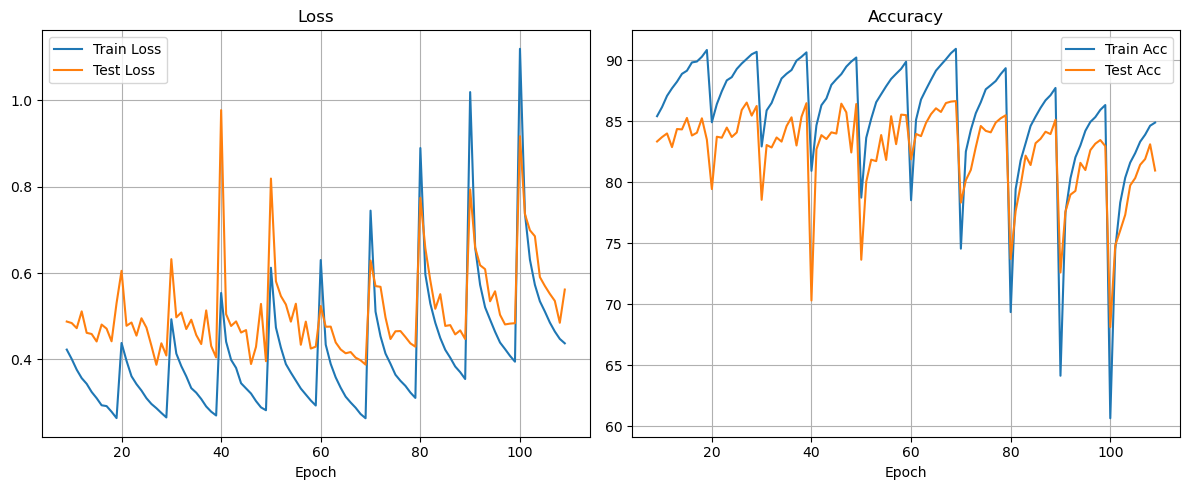

In [110]:
imp_trainer.plot_metrics()

In [63]:
imp_1_metrics_data = pd.concat([
    pd.DataFrame(imp_trainer.test_losses).rename(columns = {0:'imp_test_losses'}),
    pd.DataFrame(imp_trainer.train_losses).rename(columns = {0:'imp_train_losses'}),
    pd.DataFrame(imp_trainer.test_accs).rename(columns = {0:'imp_test_accs'}),
    pd.DataFrame(imp_trainer.train_accs).rename(columns = {0:'imp_train_accs'}),
], axis = 1).iloc[9:]

# Ансамбль IMP

Авторы сравнивают SWAMP с ансамблем из IMP: обучаются $n$ независимых классификатора с IMP прунингом

In [ ]:
class IMPEnsembleTrainer:
    def __init__(self, model, trainloader, testloader,
                 pruning_ratio=0.2, n=3, device='cuda'):
        self.n = n  # количество моделей в ансамбле
        self.models = []
        self.trainers = []
        self.device = device
        self.pruning_ratio = pruning_ratio
        self.history = []  # сохраняем логи по каждой итерации прунинга

        # для каждой модели храним свои состояния
        self.initial_states = []  # начальные веса каждой модели
        self.matching_tickets = []  # matching tickets для каждой модели
        self.masks = []  # маски для каждой модели

        for i in range(n):
            model_i = copy.deepcopy(model).to(device)

            criterion = nn.CrossEntropyLoss()
            optimizer = torch.optim.SGD(model_i.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4)
            scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[60, 120, 160], gamma=0.2)

            trainer_i = Trainer(model_i, trainloader, testloader, criterion, optimizer, scheduler)

            self.models.append(model_i)
            self.trainers.append(trainer_i)
            self.initial_states.append(self._get_weights(model_i))
            self.matching_tickets.append(None)  # пока не обучен ticket то None
            self.masks.append(self._initialize_masks(model_i))

    def _get_weights(self, model):
        return {k: v.clone().detach() for k, v in model.state_dict().items()}

    def _initialize_masks(self, model):
        return {
            name: torch.ones_like(param, dtype=torch.bool)
            for name, param in model.named_parameters()
            if "weight" in name
        }

    def _apply_mask(self, model, mask):
        with torch.no_grad():
            for name, param in model.named_parameters():
                if name in mask:
                    param.data *= mask[name]

    def _prune(self, model, mask):
        for name, param in model.named_parameters():
            if name in mask:
                current_weights = param.data[mask[name]]
                k = int(current_weights.numel() * self.pruning_ratio)
                if k == 0:
                    continue
                threshold = current_weights.abs().kthvalue(k).values
                new_mask = (param.data.abs() > threshold) & mask[name]
                mask[name] = new_mask

    def _reset_to_ticket(self, model_idx):
        self.models[model_idx].load_state_dict(self.matching_tickets[model_idx])
        self._apply_mask(self.models[model_idx], self.masks[model_idx])

    def _log_sparsity(self, mask, iteration, model_idx):
        total_params = 0
        zero_params = 0
        for m in mask.values():
            total_params += m.numel()
            zero_params += (~m).sum().item()
        sparsity = 100 * zero_params / total_params
        print(f"[Model {model_idx} | IMP Iteration {iteration}] Sparsity: {sparsity:.2f}% ({total_params - zero_params} / {total_params} non-zero)")

    def _log_iteration_metrics(self, iteration, testloader):
        total_params_all = 0
        zero_params_all = 0

        for mask in self.masks:
            for m in mask.values():
                total_params_all += m.numel()
                zero_params_all += (~m).sum().item()

        mean_sparsity = 100 * zero_params_all / total_params_all
        total_nonzero_params = total_params_all - zero_params_all

        loss, acc = self.evaluate_ensemble(testloader, return_metrics=True)

        self.history.append({
            "iteration": iteration,
            "mean_sparsity_percent": mean_sparsity,
            "total_nonzero_params": total_nonzero_params,
            "ensemble_loss": loss,
            "ensemble_acc": acc
        })

        print(f"\n Iteration {iteration} | Mean Sparsity: {mean_sparsity:.2f}% "
              f"| Non-zero Params (total): {total_nonzero_params} "
              f"| Ensemble Loss: {loss:.4f} | Acc: {acc:.2f}%")

    def run(self, C=5, T=20, T0=5):
        # получаем matching ticket для каждой модели
        print(f"\n[IMP Ensemble] Step 1: Getting matching tickets (T0={T0})...")
        for i in range(self.n):
            print(f"\n→ Model {i + 1}/{self.n}")
            self.models[i].load_state_dict(self.initial_states[i]) # загрузка начальных весов
            for epoch in range(1, T0 + 1):
                self.trainers[i].train(epoch) # Обучение модели i
                self.trainers[i].test()
                self.trainers[i].scheduler.step()
            self.matching_tickets[i] = self._get_weights(self.models[i]) # сохранение matching ticket для модели

        # собственно imp
        for c in range(1, C + 1):
            print(f"\n=== [IMP Ensemble Iteration {c}/{C}] ===")

            for i in range(self.n):
                print(f"\n→ Model {i + 1}/{self.n}")
                self._reset_to_ticket(i)
                for epoch in range(1, T + 1):
                    self.trainers[i].train(epoch)
                    self.trainers[i].test()
                    self.trainers[i].scheduler.step()

                self._prune(self.models[i], self.masks[i])
                self._log_sparsity(self.masks[i], c, i + 1)

            self._log_iteration_metrics(c, self.trainers[0].testloader)

    def predict_ensemble(self, x):
        with torch.no_grad():
            logits = [model(x.to(self.device)) for model in self.models]
            avg_logits = torch.stack(logits).mean(dim=0)
            return avg_logits

    def evaluate_ensemble(self, testloader, return_metrics=False):
        for model in self.models:
            model.eval()

        total = 0
        correct = 0
        total_loss = 0

        with torch.no_grad():
            for images, labels in testloader:
                images = images.to(self.device)
                labels = labels.to(self.device)
                outputs = self.predict_ensemble(images)
                loss = F.cross_entropy(outputs, labels)
                preds = outputs.argmax(dim=1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
                total_loss += loss.item() * labels.size(0)

        avg_loss = total_loss / total
        acc = 100. * correct / total

        if return_metrics:
            return avg_loss, acc
        else:
            print(f"Ensemble Test | Loss: {avg_loss:.4f} | Acc: {acc:.2f}%")

### IMP-2

In [ ]:
# Инициализация ансамбля
ensemble_2_10_10_10 = IMPEnsembleTrainer(
    model=WideResNet(depth=28, widen_factor=2),
    trainloader=trainloader,
    testloader=testloader,
    pruning_ratio=0.2,
    n=2,  # количество моделей в ансамбле
    device=device
)

# c итераций по t эпох, тикеты обучается t0
ensemble_2_10_10_10.run(C=10, T=10, T0=10)

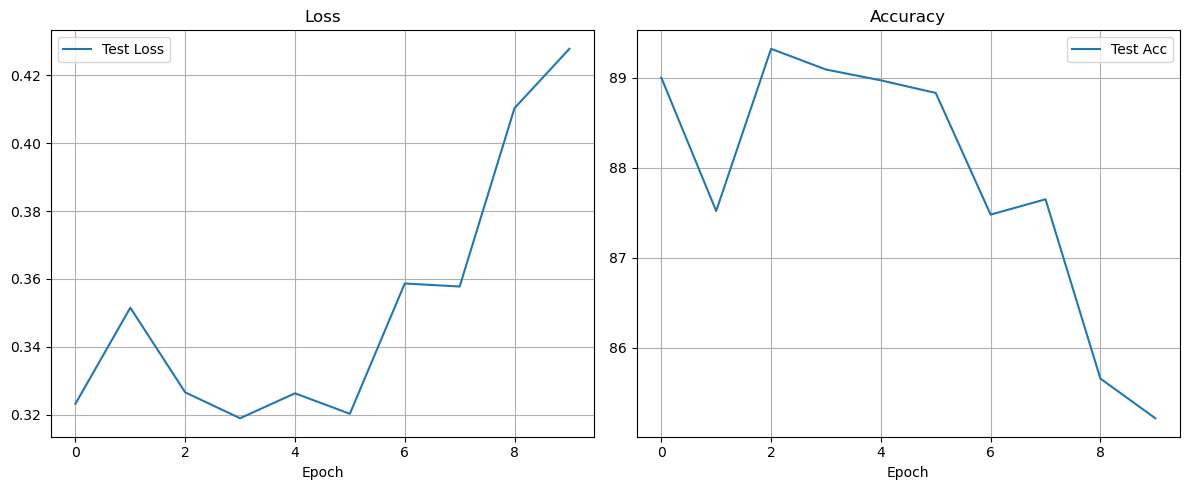

In [160]:
ensemble_2_10_10_10_history = pd.read_csv(ensemble_2_10_10_10.history, index=False)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(ensemble_2_10_10_10_history.ensemble_loss, label='Test Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ensemble_2_10_10_10_history.ensemble_acc, label='Test Acc')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

### IMP-3

In [ ]:
# Инициализация ансамбля
ensemble_3_10_10_10 = IMPEnsembleTrainer(
    model=WideResNet(depth=28, widen_factor=2),
    trainloader=trainloader,
    testloader=testloader,
    pruning_ratio=0.2,
    n=3,  # количество моделей в ансамбле
    device=device
)

# c итераций по t эпох, тикет обучается t0
ensemble_3_10_10_10.run(C=10, T=10, T0=10)

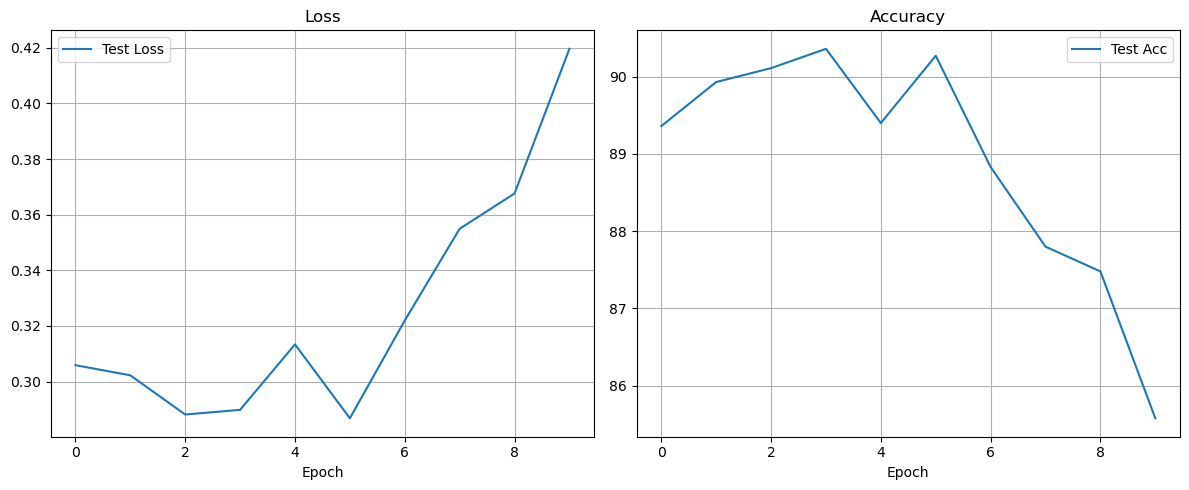

In [164]:
ensemble_3_10_10_10_history = pd.read_csv(ensemble_3_10_10_10.history, index=False)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(ensemble_3_10_10_10_history.ensemble_loss, label='Test Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ensemble_3_10_10_10_history.ensemble_acc, label='Test Acc')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()

# SWAMP (SPARSE WEIGHT AVERAGING WITH MULTIPLE PARTICLES FOR ITERATIVE MAGNITUDE PRUNING)
### (Moonseok С. et al., 2024)

In [123]:
import math
from collections import defaultdict

class SWAMPTrainer(IMPTrainer):
    def __init__(self, model, trainer, pruning_ratio=0.2, num_particles=5, ticket_epochs=5):
        super().__init__(model, trainer, pruning_ratio)
        self.num_particles = num_particles
        self.ticket_epochs = ticket_epochs

        self.eval_log = []

        print(f"\n[SWAMP] Pretraining to get matching ticket (T₀ = {self.ticket_epochs} epochs)...")
        for epoch in range(1, self.ticket_epochs + 1):
            self.trainer.train(epoch)
            self.trainer.test()
            self.trainer.scheduler.step()
        self.matching_ticket = {k: v.clone().detach() for k, v in self.model.state_dict().items()}

    def _prune_from_weights(self, weights):

      for name, param in self.model.named_parameters():
          if name in self.masks:
              weight_data = weights[name][self.masks[name]]
              k = int(weight_data.numel() * self.pruning_ratio)
              if k == 0:
                  continue
              threshold = weight_data.abs().kthvalue(k).values
              new_mask = (weights[name].abs() > threshold) & self.masks[name]
              self.masks[name] = new_mask

    def run(self, C=10, T=10):
        base_seed = 42
        for c in range(1, C + 1):
            print(f"\n[SWAMP Iteration {c}/{C}]")

            particle_weights = None

            for n in range(1, self.num_particles + 1):
                print(f" Particle {n}/{self.num_particles}")

                # Разные источники стохастичности
                torch.manual_seed(base_seed + n)
                np.random.seed(base_seed + n)
                random.seed(base_seed + n)

                self.model.load_state_dict(self.matching_ticket)
                self._apply_mask()

                swa_accumulator = defaultdict(float)
                swa_count = 0
                swa_start_epoch = math.floor(0.75 * T) + 1

                for epoch in range(1, T + 1):
                    self.trainer.train(epoch)
                    self.trainer.test()
                    self.trainer.scheduler.step()

                    if epoch >= swa_start_epoch:
                        for name, param in self.model.state_dict().items():
                            swa_accumulator[name] += param.clone().detach()
                        swa_count += 1

                # Усреднение по последним 25% эпох
                for name in swa_accumulator:
                    swa_accumulator[name] /= swa_count

                if particle_weights is None:
                    particle_weights = swa_accumulator
                else:
                    for k in particle_weights:
                        particle_weights[k] += swa_accumulator[k]

            # Усреднение по всем частицам
            for k in particle_weights:
                particle_weights[k] /= self.num_particles
            self.model.load_state_dict(particle_weights)

            # Прунинг по усреднённым весам
            self._prune_from_weights(particle_weights)
            self._log_sparsity(c)

            # Прогон модели после прунинга
            self.model.eval()
            correct, total, running_loss = 0, 0, 0
            with torch.no_grad():
                for inputs, targets in self.trainer.testloader:
                    inputs, targets = inputs.to(device), targets.to(device)
                    outputs = self.model(inputs)
                    loss = self.trainer.criterion(outputs, targets)
                    running_loss += loss.item()
                    _, predicted = outputs.max(1)
                    total += targets.size(0)
                    correct += predicted.eq(targets).sum().item()

            test_loss = running_loss / len(self.trainer.testloader)
            test_acc = 100. * correct / total

            # Сохраняем результат
            self.eval_log.append({
                "iteration": c,
                "test_loss": test_loss,
                "test_acc": test_acc
            })
            print(f"[SWAMP Iteration {c}] Averaged particles eval {test_loss:.3f} | Acc: {test_acc:.2f}%")



In [ ]:
wrn28_2_swamp_model_cos = WideResNet(depth=28, widen_factor=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(wrn28_2_swamp_model_cos.parameters(), lr=0.05, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

wrn28_2_swamp_trainer_cos = Trainer(
    model=wrn28_2_swamp_model_cos,
    trainloader=trainloader,
    testloader=testloader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler
)

swamp_reduce_cos = SWAMPTrainer(
    model=wrn28_2_swamp_model_cos,
    trainer=wrn28_2_swamp_trainer_cos,
    pruning_ratio=0.2,
    num_particles=3,
    ticket_epochs = 10,
)

In [ ]:
swamp_reduce_cos.run(C=10, T=10)

In [131]:
swamp_metrics = swamp_reduce_cos.eval_log

,iteration,test_loss,test_acc
0,1,0.345906,87.53
1,2,0.330081,88.74
2,3,0.339110,88.37
3,4,0.329431,88.90
4,5,0.348996,88.06
5,6,0.361058,87.58
6,7,0.377830,87.02
7,8,0.454942,84.25
8,9,0.470636,83.90
9,10,1.210379,82.34


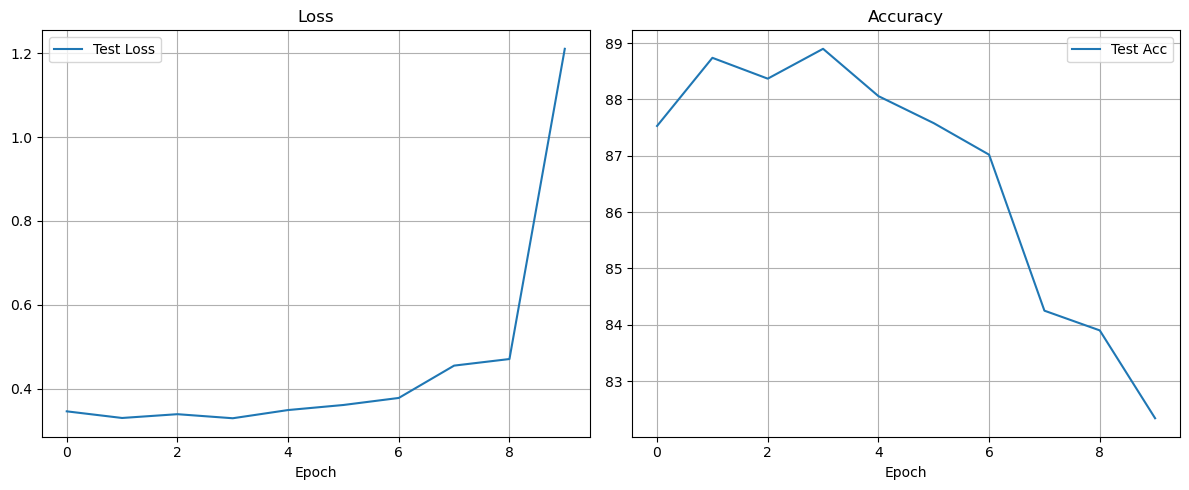

In [141]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(swamp_metrics.test_loss, label='Test Loss')
plt.title('Loss')
plt.xlabel('Epoch')
plt.grid()
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(swamp_metrics.test_acc, label='Test Acc')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.grid()
plt.legend()

plt.tight_layout()
plt.show()